# Classification - Credit Card Fraud

**Goal:** predict `Class` (1 = fraud, 0 = legit) using KNN, Logistic Regression, Naive Bayes, Decision Tree and SVM.

The data is imbalanced, so we balance the **training set only**. `Time` and `Amount` are already scaled in preprocessing.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = pd.read_csv('../Data/creditcard_clean.csv')
print(data['Class'].value_counts())

Class
0    283253
1       473
Name: count, dtype: int64


## Train-test split

In [4]:
x = data.drop(columns=['Class', 'Hour'], errors='ignore')
y = data['Class']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print(x_train.shape, x_test.shape)

(226980, 30) (56746, 30)


## Balance the training data
Keep all fraud rows and take the same number of random legit rows.

In [5]:
train = x_train.copy()
train['Class'] = y_train

class_1 = train[train['Class'] == 1]
class_0 = train[train['Class'] == 0].sample(len(class_1), random_state=42)

train_bal = pd.concat([class_0, class_1])
x_bal = train_bal.drop('Class', axis=1)
y_bal = train_bal['Class']

print(y_bal.value_counts())

Class
0    378
1    378
Name: count, dtype: int64


## 1. KNN

In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_bal, y_bal)
y_pred = knn.predict(x_test)

print('accuracy:', accuracy_score(y_test, y_pred))
print('confusion matrix:')
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

accuracy: 0.9762802664504987
confusion matrix:
[[55319  1332]
 [   14    81]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.85      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.91      0.55     56746
weighted avg       1.00      0.98      0.99     56746



## 2. Logistic Regression

In [7]:
lr = LogisticRegression(max_iter=1000)
lr.fit(x_bal, y_bal)
y_pred = lr.predict(x_test)

print('accuracy:', accuracy_score(y_test, y_pred))
print('confusion matrix:')
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

accuracy: 0.9724209635921475
confusion matrix:
[[55098  1553]
 [   12    83]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.98     56746



## 3. Naive Bayes

In [8]:
nb = GaussianNB()
nb.fit(x_bal, y_bal)
y_pred = nb.predict(x_test)

print('accuracy:', accuracy_score(y_test, y_pred))
print('confusion matrix:')
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

accuracy: 0.9689845980333416
confusion matrix:
[[54909  1742]
 [   18    77]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56651
           1       0.04      0.81      0.08        95

    accuracy                           0.97     56746
   macro avg       0.52      0.89      0.53     56746
weighted avg       1.00      0.97      0.98     56746



## 4. Decision Tree

In [9]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_bal, y_bal)
y_pred = dt.predict(x_test)

print('accuracy:', accuracy_score(y_test, y_pred))
print('confusion matrix:')
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

accuracy: 0.8965037183237585
confusion matrix:
[[50784  5867]
 [    6    89]]
              precision    recall  f1-score   support

           0       1.00      0.90      0.95     56651
           1       0.01      0.94      0.03        95

    accuracy                           0.90     56746
   macro avg       0.51      0.92      0.49     56746
weighted avg       1.00      0.90      0.94     56746



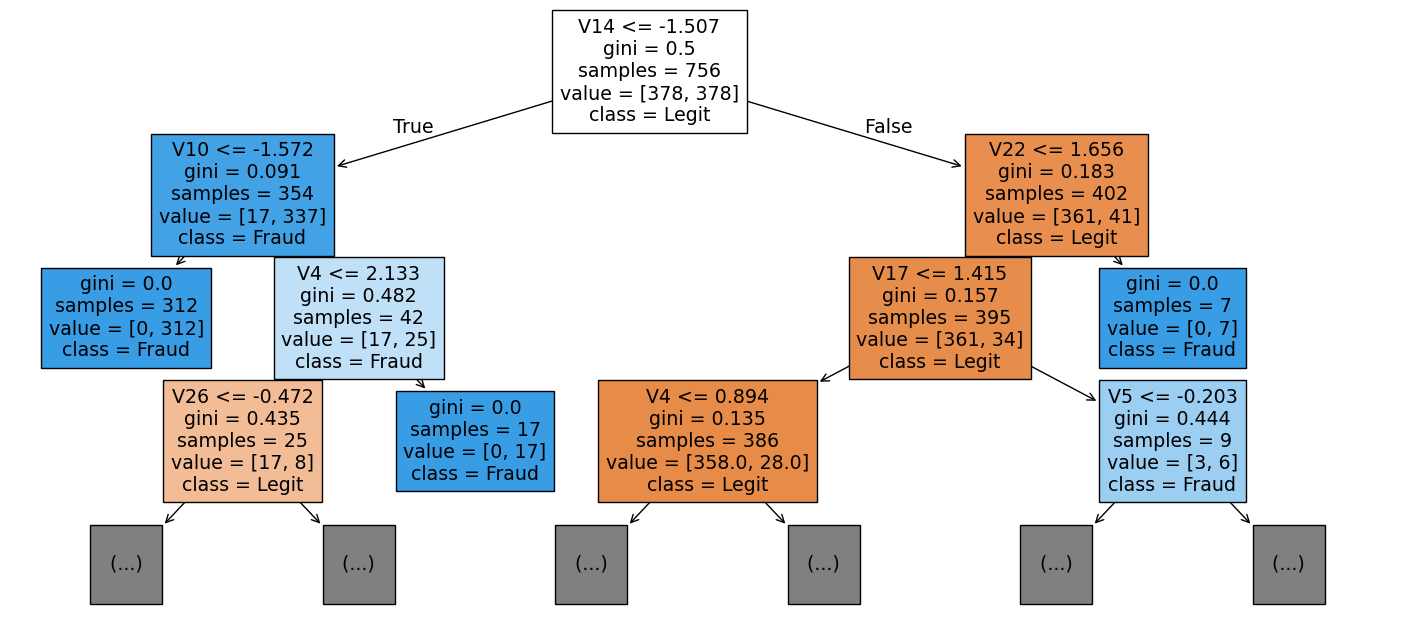

In [10]:
# tree diagram (top 3 levels)
plt.figure(figsize=(18, 8))
plot_tree(dt, feature_names=list(x_bal.columns), class_names=['Legit', 'Fraud'], filled=True, max_depth=3)
plt.show()

## 5. SVM

In [11]:
svm = SVC()
svm.fit(x_bal, y_bal)
y_pred = svm.predict(x_test)

print('accuracy:', accuracy_score(y_test, y_pred))
print('confusion matrix:')
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

accuracy: 0.986430761639587
confusion matrix:
[[55896   755]
 [   15    80]]
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56651
           1       0.10      0.84      0.17        95

    accuracy                           0.99     56746
   macro avg       0.55      0.91      0.58     56746
weighted avg       1.00      0.99      0.99     56746



## Conclusion
- In the confusion matrix, rows are actual and columns are predicted: `[[TN, FP], [FN, TP]]`.
- Accuracy alone is misleading because the test data is imbalanced. Look at the **recall** of class 1 (fraud) in each report. It shows how many real frauds were caught.
- Precision for fraud is low because we balanced only the training data, so many legit transactions get flagged.
- Best model = highest fraud recall with a reasonable fraud F1.